In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/digit-recognizer/sample_submission.csv
/kaggle/input/digit-recognizer/train.csv
/kaggle/input/digit-recognizer/test.csv
/kaggle/input/datasets/basantbansal/numbersix/six.jpeg


In [2]:

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns
%matplotlib inline 

np.random.seed(2)

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import itertools

from tensorflow.keras.utils import to_categorical
from keras.models import Sequential 
from keras.layers import Dense, Dropout, Flatten, Conv2D, MaxPool2D,GlobalAveragePooling2D,Input
from keras.optimizers import RMSprop
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from keras.callbacks import ReduceLROnPlateau ,EarlyStopping
from tensorflow.keras.layers import BatchNormalization

sns.set(style='white',context='notebook',palette='deep')

2026-02-27 13:21:11.417360: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1772198471.622553      23 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1772198471.674018      23 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1772198472.119619      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772198472.119676      23 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1772198472.119679      23 computation_placer.cc:177] computation placer alr

In [3]:
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.models import Model
import tensorflow as tf

In [4]:
train = pd.read_csv("/kaggle/input/digit-recognizer/train.csv")
test = pd.read_csv("/kaggle/input/digit-recognizer/test.csv")

In [5]:
Y_train = train['label']
X_train = train.drop(labels = ['label'],axis=1)

del train

# g = sns.countplot(Y_train)

# Y_train.value_counts()

In [6]:
X_train.isnull().any().describe()


count       784
unique        1
top       False
freq        784
dtype: object

In [7]:
test.isnull().any().describe()

count       784
unique        1
top       False
freq        784
dtype: object

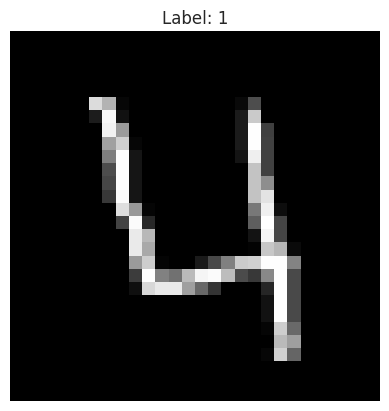

In [8]:
plt.imshow(X_train.iloc[3].values.reshape(28, 28), cmap='gray')
plt.title(f"Label: {Y_train.iloc[0]}")
plt.axis('off')
plt.show()

In [9]:
X_train = X_train/255.0
test = test/255.0

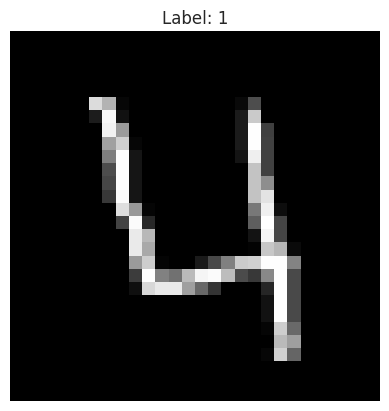

In [10]:
plt.imshow(X_train.iloc[3].values.reshape(28, 28), cmap='gray')
plt.title(f"Label: {Y_train.iloc[0]}")
plt.axis('off')
plt.show()

In [11]:
X_train = X_train.values.reshape(-1,28,28,1)
test=test.values.reshape(-1,28,28,1)

In [12]:
Y_train = to_categorical(Y_train,num_classes=10)

In [13]:
random_seed = 2

In [14]:
X_train,X_val,Y_train,Y_val = train_test_split(X_train,Y_train,test_size=0.1,random_state=random_seed)

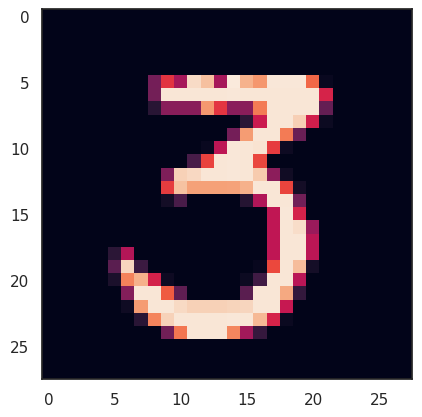

In [15]:
g = plt.imshow(X_train[3][:,:,0])

In [16]:
# X_train_resized = tf.image.resize(X_train, [75, 75])
# X_train_resized = tf.repeat(X_train_resized, 3, axis=-1)  # grayscale to RGB

# X_val_resized = tf.image.resize(X_val, [75, 75])
# X_val_resized = tf.repeat(X_val_resized, 3, axis=-1)

# test_resized = tf.image.resize(test, [75, 75])
# test_resized = tf.repeat(test_resized, 3, axis=-1)

In [17]:
# base_model = InceptionV3(
#     weights='imagenet',
#     include_top=False,        # remove Google's classifier
#     input_shape=(75, 75, 3)
# )

# # Step 3 - Freeze base
# base_model.trainable = False

# # Step 4 - Add your own classification head
# inputs = Input(shape=(75, 75, 3))
# x = base_model(inputs, training=False)
# x = GlobalAveragePooling2D()(x)
# x = Dense(256, activation='relu')(x)
# x = Dropout(0.5)(x)
# outputs = Dense(10, activation='softmax')(x)

# model = Model(inputs, outputs)

# # Step 5 - Phase 1 training
# model.compile(
#     optimizer='adam',
#     loss='categorical_crossentropy',
#     metrics=['accuracy']
# )

# history = model.fit(
#     X_train_resized, Y_train,
#     epochs=15,
#     validation_data=(X_val_resized, Y_val),
#     batch_size=64
# )

# # Step 6 - Unfreeze and fine tune
# base_model.trainable = True

# for layer in base_model.layers[:200]:  # keep first 200 frozen
#     layer.trainable = False

# model.compile(
#     optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
#     loss='categorical_crossentropy',
#     metrics=['accuracy']
# )

# history2 = model.fit(
#     X_train_resized, Y_train,
#     epochs=10,
#     validation_data=(X_val_resized, Y_val),
#     batch_size=64
# )

In [18]:
# # Combine both histories
# train_acc = history1.history['accuracy'] + history2.history['accuracy']
# val_acc = history1.history['val_accuracy'] + history2.history['val_accuracy']
# train_loss = history1.history['loss'] + history2.history['loss']
# val_loss = history1.history['val_loss'] + history2.history['val_loss']

# # Draw a vertical line showing where phase 1 ended and phase 2 began
# phase1_epochs = len(history1.history['accuracy'])

# fig, ax = plt.subplots(2, 1, figsize=(10, 8))

# # Accuracy plot
# ax[0].plot(train_acc, color='b', label='Training accuracy')
# ax[0].plot(val_acc, color='r', label='Validation accuracy')
# ax[0].axvline(x=phase1_epochs, color='green', linestyle='--', label='Fine tuning starts')
# ax[0].set_title('Accuracy')
# ax[0].legend(loc='best')

# # Loss plot
# ax[1].plot(train_loss, color='b', label='Training loss')
# ax[1].plot(val_loss, color='r', label='Validation loss')
# ax[1].axvline(x=phase1_epochs, color='green', linestyle='--', label='Fine tuning starts')
# ax[1].set_title('Loss')
# ax[1].legend(loc='best')

# plt.tight_layout()
# plt.show()

In [19]:
# model = Sequential([
#     Conv2D(filters=32,kernel_size=(5,5),padding='Same',activation='relu',input_shape=(28,28,1)),
#     BatchNormalization(),
#     Conv2D(filters=32,kernel_size=(5,5),padding='Same',activation='relu'),
#     BatchNormalization(),
#     MaxPool2D(pool_size=(2,2)),
#     Dropout(0.25),
#     Conv2D(filters=64,kernel_size=(3,3),padding='Same',activation='relu'),
#     BatchNormalization(),
#     Conv2D(filters=64,kernel_size=(3,3),padding='Same',activation='relu'),
#     BatchNormalization(),
#     MaxPool2D(pool_size=2,strides=2),
#     Dropout(0.25),
#     Conv2D(filters=128, kernel_size=(3,3), padding='Same', activation='relu'),  # new block
#     BatchNormalization(),
#     MaxPool2D(pool_size=2, strides=2),
#     Dropout(0.25),
    
#     Flatten(),
#     Dense(512,activation='relu'),
#     Dropout(0.5),
#     Dense(10,activation='softmax'),
# ])

In [20]:
# optimizer = RMSprop(learning_rate=0.001, rho=0.9, epsilon=1e-08)

In [21]:
# model.compile(optimizer=optimizer,loss='categorical_crossentropy',metrics=['accuracy'])

In [22]:
learning_rate_reduction = ReduceLROnPlateau(monitor='val_accuracy', 
                                            patience=3, 
                                            verbose=1, 
                                            factor=0.5, 
                                            min_lr=0.00001)

In [23]:
epochs = 50 # Turn epochs to 30 to get 0.9967 accuracy
batch_size = 86

In [24]:
datagen = ImageDataGenerator(
    featurewise_center=False,
    samplewise_center=False,
    featurewise_std_normalization=False,
    samplewise_std_normalization=False,
    zca_whitening=False,
    rotation_range=5,
    zoom_range=0.1,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=False,
    vertical_flip=False
)

datagen.fit(X_train)

In [25]:
def build_model():
    model = Sequential([
        Conv2D(filters=32,kernel_size=(5,5),padding='Same',activation='relu',input_shape=(28,28,1)),
    BatchNormalization(),
    Conv2D(filters=32,kernel_size=(5,5),padding='Same',activation='relu'),
    BatchNormalization(),
    MaxPool2D(pool_size=(2,2)),
    Dropout(0.25),
    Conv2D(filters=64,kernel_size=(3,3),padding='Same',activation='relu'),
    BatchNormalization(),
    Conv2D(filters=64,kernel_size=(3,3),padding='Same',activation='relu'),
    BatchNormalization(),
    MaxPool2D(pool_size=2,strides=2),
    Dropout(0.25),
    Conv2D(filters=128, kernel_size=(3,3), padding='Same', activation='relu'),  # new block
    BatchNormalization(),
    MaxPool2D(pool_size=2, strides=2),
    Dropout(0.25),
    
    Flatten(),
    Dense(512,activation='relu'),
    Dropout(0.5),
    Dense(10,activation='softmax'),
    ])
    
    model.compile(
        optimizer=RMSprop(learning_rate=0.001, rho=0.9, epsilon=1e-08),
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

In [26]:
# Train model 1
np.random.seed(1)
model1 = build_model()  # put your model code in a function
history1 = model1.fit(datagen.flow(X_train, Y_train, batch_size=batch_size),
                    epochs=epochs, 
                    validation_data=(X_val, Y_val),
                    verbose=2, 
                    steps_per_epoch=X_train.shape[0] // batch_size,
                    callbacks=[learning_rate_reduction])

# Train model 2  
np.random.seed(2)
model2 = build_model()
history2 = model2.fit(datagen.flow(X_train, Y_train, batch_size=batch_size),
                    epochs=epochs, 
                    validation_data=(X_val, Y_val),
                    verbose=2, 
                    steps_per_epoch=X_train.shape[0] // batch_size,
                    callbacks=[learning_rate_reduction])

# Train model 3
np.random.seed(3)
model3 = build_model()
history3 = model3.fit(datagen.flow(X_train, Y_train, batch_size=batch_size),
                    epochs=epochs, 
                    validation_data=(X_val, Y_val),
                    verbose=2, 
                    steps_per_epoch=X_train.shape[0] // batch_size,
                    callbacks=[learning_rate_reduction])

# Average predictions


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1772198495.851003      23 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15511 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Epoch 1/50


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
I0000 00:00:1772198499.555840      63 service.cc:152] XLA service 0x79f9c0003e10 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1772198499.555884      63 service.cc:160]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1772198500.110281      63 cuda_dnn.cc:529] Loaded cuDNN version 91002
I0000 00:00:1772198505.930022      63 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


439/439 - 25s - 57ms/step - accuracy: 0.8735 - loss: 0.4703 - val_accuracy: 0.8033 - val_loss: 0.9200 - learning_rate: 1.0000e-03
Epoch 2/50


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


439/439 - 0s - 748us/step - accuracy: 0.9419 - loss: 0.1312 - val_accuracy: 0.7664 - val_loss: 1.0790 - learning_rate: 1.0000e-03
Epoch 3/50
439/439 - 10s - 22ms/step - accuracy: 0.9627 - loss: 0.1409 - val_accuracy: 0.9764 - val_loss: 0.1021 - learning_rate: 1.0000e-03
Epoch 4/50
439/439 - 0s - 731us/step - accuracy: 0.9651 - loss: 0.0983 - val_accuracy: 0.9848 - val_loss: 0.0657 - learning_rate: 1.0000e-03
Epoch 5/50
439/439 - 10s - 22ms/step - accuracy: 0.9714 - loss: 0.1141 - val_accuracy: 0.9876 - val_loss: 0.0502 - learning_rate: 1.0000e-03
Epoch 6/50
439/439 - 0s - 740us/step - accuracy: 0.9535 - loss: 0.1422 - val_accuracy: 0.9852 - val_loss: 0.0790 - learning_rate: 1.0000e-03
Epoch 7/50
439/439 - 10s - 22ms/step - accuracy: 0.9738 - loss: 0.1032 - val_accuracy: 0.9883 - val_loss: 0.0416 - learning_rate: 1.0000e-03
Epoch 8/50
439/439 - 0s - 748us/step - accuracy: 0.9884 - loss: 0.0209 - val_accuracy: 0.9890 - val_loss: 0.0433 - learning_rate: 1.0000e-03
Epoch 9/50
439/439 - 10s

In [27]:
# # early_stopping = EarlyStopping(
# #     monitor='val_accuracy',
# #     patience=5,
# #     restore_best_weights=True,  # goes back to best weights automatically
# #     verbose=1
# # )

# history = model.fit(datagen.flow(X_train, Y_train, batch_size=batch_size),
#                     epochs=epochs, 
#                     validation_data=(X_val, Y_val),
#                     verbose=2, 
#                     steps_per_epoch=X_train.shape[0] // batch_size,
#                     callbacks=[learning_rate_reduction])

In [28]:
# fig, ax = plt.subplots(2, 1, figsize=(10, 8))

# ax[0].plot(history.history['loss'], color='b', label="Training loss")
# ax[0].plot(history.history['val_loss'], color='r', label="Validation loss")
# ax[0].legend(loc='best', shadow=True)
# ax[0].set_title("Loss")

# ax[1].plot(history.history['accuracy'], color='b', label="Training accuracy")
# ax[1].plot(history.history['val_accuracy'], color='r', label="Validation accuracy")
# ax[1].legend(loc='best', shadow=True)
# ax[1].set_title("Accuracy")

# plt.tight_layout()
# plt.show()

In [29]:
# print(history.history.keys())
# print(len(history.history['loss']))

132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step


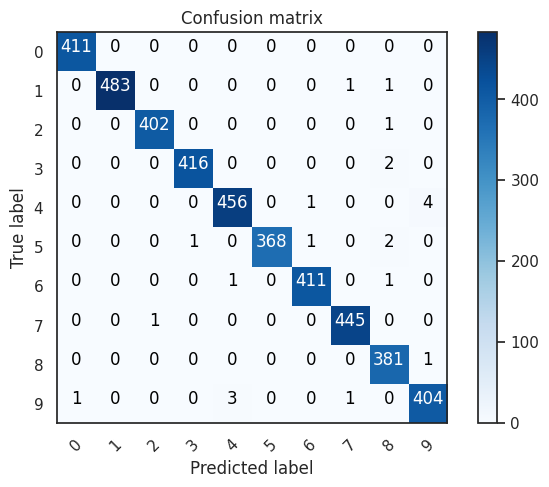

In [30]:
# Look at confusion matrix 

def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, cm[i, j],
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

# Predict the values from the validation dataset
Y_pred = model1.predict(X_val)
# Convert predictions classes to one hot vectors 
Y_pred_classes = np.argmax(Y_pred,axis = 1) 
# Convert validation observations to one hot vectors
Y_true = np.argmax(Y_val,axis = 1) 
# compute the confusion matrix
confusion_mtx = confusion_matrix(Y_true, Y_pred_classes) 
# plot the confusion matrix
plot_confusion_matrix(confusion_mtx, classes = range(10)) 

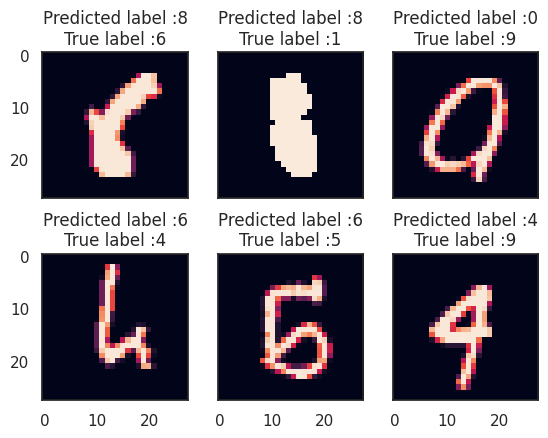

In [31]:
# Display some error results 

# Errors are difference between predicted labels and true labels
errors = (Y_pred_classes - Y_true != 0)

Y_pred_classes_errors = Y_pred_classes[errors]
Y_pred_errors = Y_pred[errors]
Y_true_errors = Y_true[errors]
X_val_errors = X_val[errors]

def display_errors(errors_index,img_errors,pred_errors, obs_errors):
    """ This function shows 6 images with their predicted and real labels"""
    n = 0
    nrows = 2
    ncols = 3
    fig, ax = plt.subplots(nrows,ncols,sharex=True,sharey=True)
    for row in range(nrows):
        for col in range(ncols):
            error = errors_index[n]
            ax[row,col].imshow((img_errors[error]).reshape((28,28)))
            ax[row,col].set_title("Predicted label :{}\nTrue label :{}".format(pred_errors[error],obs_errors[error]))
            n += 1

# Probabilities of the wrong predicted numbers
Y_pred_errors_prob = np.max(Y_pred_errors,axis = 1)

# Predicted probabilities of the true values in the error set
true_prob_errors = np.diagonal(np.take(Y_pred_errors, Y_true_errors, axis=1))

# Difference between the probability of the predicted label and the true label
delta_pred_true_errors = Y_pred_errors_prob - true_prob_errors

# Sorted list of the delta prob errors
sorted_dela_errors = np.argsort(delta_pred_true_errors)

# Top 6 errors 
most_important_errors = sorted_dela_errors[-6:]

# Show the top 6 errors
display_errors(most_important_errors, X_val_errors, Y_pred_classes_errors, Y_true_errors)

In [32]:
# results = model.predict(test)

# # TTA - predict 10 times with augmentation and average
# tta_steps = 10
# predictions = []

# for i in range(tta_steps):
#     preds = model.predict(
#         datagen.flow(test, batch_size=batch_size, shuffle=False)
#     )
#     predictions.append(preds)

# # Average all predictions
# final_predictions = np.mean(predictions, axis=0)
# results = np.argmax(final_predictions, axis=1)
# results = pd.Series(results, name="Label")

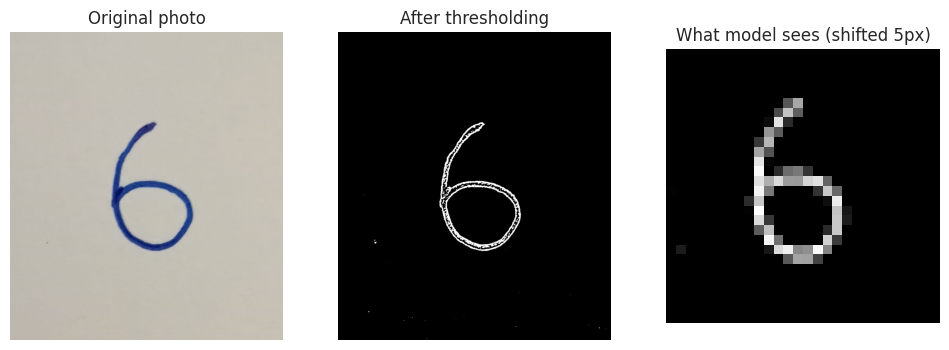

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 586ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 622ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 622ms/step


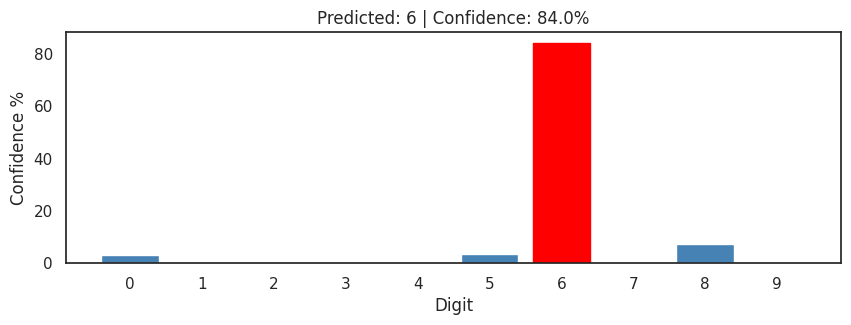

Predicted digit: 6
Confidence: 84.0%


In [33]:
import cv2
def shift_image(img, shift_down=3, shift_right=0):
    M = np.float32([[1, 0, shift_right], [0, 1, shift_down]])
    shifted = cv2.warpAffine(img, M, (img.shape[1], img.shape[0]))
    return shifted

def preprocess_like_mnist(image_path, shift_down=3):
    img = cv2.imread(image_path)
    img_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    img_blur = cv2.GaussianBlur(img_gray, (5,5), 0)
    img_thresh = cv2.adaptiveThreshold(
        img_blur, 255,
        cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
        cv2.THRESH_BINARY_INV,
        11, 2
    )
    coords = cv2.findNonZero(img_thresh)
    x, y, w, h = cv2.boundingRect(coords)
    digit_crop = img_thresh[y:y+h, x:x+w]
    pad = int(max(w, h) * 0.01)
    digit_padded = cv2.copyMakeBorder(
        digit_crop, pad, pad, pad, pad,
        cv2.BORDER_CONSTANT, value=0
    )
    img_resized = cv2.resize(digit_padded, (28, 28),
                             interpolation=cv2.INTER_AREA)
    
    # Shift BEFORE plotting so you can see shifted result
    img_resized = shift_image(img_resized, shift_down=shift_down)

    # Plot after everything including shift
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[0].set_title('Original photo')
    axes[0].axis('off')
    axes[1].imshow(img_thresh, cmap='gray')
    axes[1].set_title('After thresholding')
    axes[1].axis('off')
    axes[2].imshow(img_resized, cmap='gray')
    axes[2].set_title(f'What model sees (shifted {shift_down}px)')
    axes[2].axis('off')
    plt.show()

    return img_resized

def predict_from_image(image_path):
    img_resized = preprocess_like_mnist(image_path,shift_down=5)
    
    img_normalized = img_resized / 255.0
    img_final = img_normalized.reshape(1, 28, 28, 1)
    
    # Ensemble prediction
    pred1 = model1.predict(img_final)
    pred2 = model2.predict(img_final)
    pred3 = model3.predict(img_final)
    final = (pred1 + pred2 + pred3) / 3
    
    digit = np.argmax(final)
    confidence = np.max(final) * 100
    
    # Bar chart
    plt.figure(figsize=(10, 3))
    bars = plt.bar(range(10), final[0] * 100, color='steelblue')
    bars[digit].set_color('red')
    plt.xticks(range(10))
    plt.xlabel('Digit')
    plt.ylabel('Confidence %')
    plt.title(f'Predicted: {digit} | Confidence: {confidence:.1f}%')
    plt.show()
    
    print(f'Predicted digit: {digit}')
    print(f'Confidence: {confidence:.1f}%')

predict_from_image('/kaggle/input/datasets/basantbansal/numbersix/six.jpeg')


In [34]:
pred1 = model1.predict(test)
pred2 = model2.predict(test)
pred3 = model3.predict(test)

final = (pred1 + pred2 + pred3) / 3
results = np.argmax(final, axis=1)
results = pd.Series(results, name="Label")

875/875 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
875/875 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step
875/875 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step


In [35]:
submission = pd.concat([pd.Series(range(1,28001),name="ImageId"),results],axis=1)

submission.to_csv("cnn_mnist_datagen.csv",index=False)